# ⚡ LAB: Forecasting Strategies


**Learning goals:**
- Compare **Direct** and **Recursive** multi-step electricity-demand forecasting.
- Examine the effect of forecast horizon on prediction error.
- Compare **Sliding** and **Expanding** training windows using time-ordered backtesting.
- Report **NRMSE (%)** and interpret results without data leakage.

**Dataset:** Elering hourly electricity demand in Estonia, 2022. The code reads the public CSV directly from the course GitHub repository. No manual download is required.

**Instructions:** Run cells in order. Look for `TODO` comments: most code is provided, and your job is to **change parameters, compare plots, and explain what happened**.



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display
from datetime import timedelta

plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.grid': True, 'grid.alpha': 0.20})
TZ = 'Europe/Tallinn'


## Data loading — common setup

Use the GitHub CSV directly. We build the time index from UTC epoch seconds, then display it in Tallinn local time so daylight-saving-time duplicates are handled correctly.

In [6]:
# GitHub-first, without requiring any local CSV files.
DATA_URL = (
    'https://raw.githubusercontent.com/drmatson/energy_informatics/'
    'main/data/electricity-production%20and%20consumption_2022.csv'
)
raw = pd.read_csv(DATA_URL, sep=';', decimal=',')

# The dataset contains an unambiguous UTC timestamp. Convert it to Tallinn time
# to avoid daylight-saving-time ambiguity in the human-readable local timestamp.
local_time = pd.to_datetime(raw['Ajatempel (UTC)'], unit='s', utc=True).dt.tz_convert(TZ)
demand = pd.Series(raw['Tarbimine'].to_numpy(dtype=float),
                   index=pd.DatetimeIndex(local_time), name='Demand').sort_index()
demand = demand.groupby(level=0).mean().asfreq('h').ffill()


assert demand.index.is_unique, 'Hourly timestamps must be unique.'
assert not demand.isna().any(), 'Unexpected gaps in Elering hourly data.'
print(f'Loaded {len(demand):,} hourly values from {demand.index.min()} to {demand.index.max()}')
display(demand.head().to_frame())


Loaded 8,760 hourly values from 2022-01-01 00:00:00+02:00 to 2022-12-31 23:00:00+02:00


,Demand
Ajatempel (UTC),
2022-01-01 00:00:00+02:00,899.4
2022-01-01 01:00:00+02:00,892.1
2022-01-01 02:00:00+02:00,874.3
2022-01-01 03:00:00+02:00,860.1
2022-01-01 04:00:00+02:00,842.7


## Forecasting functions — provided code

Read the comments and run this cell. You are **not** expected to write a forecasting library from scratch.

In [7]:
# Core functions — ready to use; you do not need to implement the models from scratch.
LAGS = (1, 2, 3, 24, 48, 168)


def calendar_features(timestamp):
    """Known in advance: hour-of-day and day-of-week."""
    hour = timestamp.hour
    weekday = timestamp.dayofweek
    return [
        np.sin(2 * np.pi * hour / 24),
        np.cos(2 * np.pi * hour / 24),
        np.sin(2 * np.pi * weekday / 7),
        np.cos(2 * np.pi * weekday / 7),
    ]


def direct_features(signal, origin, horizon_step):
    """Features available at forecast origin (no future observed Demand)."""
    past_values = [float(signal.loc[origin - timedelta(hours=k)]) for k in LAGS]
    forecast_timestamp = origin + timedelta(hours=horizon_step - 1)
    return np.asarray(past_values + calendar_features(forecast_timestamp), dtype=float)


def model_factory():
    # Same model family for both strategies; scaling is fitted on TRAINING data only.
    return make_pipeline(StandardScaler(), Ridge(alpha=3.0))


def forecast_direct(signal, origin, train_start, horizon=24):
    """Train one model for each step h, using only days before origin."""
    candidate_origins = pd.date_range(
        train_start, origin - pd.DateOffset(days=1), freq='D'
    )
    preds = []
    for h in range(1, horizon + 1):
        X, y = [], []
        for past_origin in candidate_origins:
            target_t = past_origin + timedelta(hours=h - 1)
            if target_t >= origin:  # never use future test targets for training
                continue
            try:
                x_row = direct_features(signal, past_origin, h)
                y_val = float(signal.loc[target_t])
            except KeyError:
                continue
            X.append(x_row)
            y.append(y_val)
        if len(y) < 5:
            raise ValueError(f'Only {len(y)} examples for horizon {h}; extend train window.')
        mdl = model_factory()
        mdl.fit(np.asarray(X), np.asarray(y))
        preds.append(float(mdl.predict(direct_features(signal, origin, h)[None, :])[0]))
    return np.asarray(preds)


def forecast_recursive(signal, origin, train_start, horizon=24):
    """Train one 1-step model, roll forward by feeding predictions into lag features."""
    train_times = signal.loc[train_start : origin - timedelta(hours=1)].index
    X, y = [], []
    for t in train_times:
        try:
            lag_values = [float(signal.loc[t - timedelta(hours=k)]) for k in LAGS]
        except KeyError:
            continue
        X.append(lag_values + calendar_features(t))
        y.append(float(signal.loc[t]))
    if len(y) < 100:
        raise ValueError('Insufficient hourly training examples.')
    mdl = model_factory()
    mdl.fit(np.asarray(X), np.asarray(y))

    history = list(signal.loc[:origin - timedelta(hours=1)].to_numpy(dtype=float))
    preds = []
    for h in range(horizon):
        forecast_t = origin + timedelta(hours=h)
        x = [history[-k] for k in LAGS] + calendar_features(forecast_t)
        yhat = float(mdl.predict(np.asarray(x, dtype=float)[None, :])[0])
        preds.append(yhat)
        history.append(yhat)  # critical recursive feedback step
    return np.asarray(preds)


def actual_values(signal, origin, horizon=24):
    target_index = pd.date_range(origin, periods=horizon, freq='h')
    return signal.loc[target_index].to_numpy(dtype=float)


def nrmse(y_true, y_pred):
    """NRMSE (%) = 100 * RMSE / mean(actual demand)."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    return 100 * rmse / np.mean(y_true)  # demand is positive


## Exercise 1 — Direct vs. Recursive: does the horizon matter?



Both forecasters make predictions at the **same forecast origin** (00:00 Tallinn time). The historical 30-day window ends **before** the forecast starts. Direct trains one Ridge model for each future hour; Recursive trains one next-hour Ridge model and rolls it forward.

**Important:** The figure below is an *illustration of possible error behaviour*, **not actual results** from the Elering data. Your graphs after running the code will show actual measured errors.


### Your tasks

1. Run the baseline setup for **6, 12, and 24 hours**.
2. **TODO 1:** Change the list of horizons (for example, test `3, 6, 12, 24`).
3. **TODO 2:** Repeat with a different training-history length (e.g. `60` days instead of `30`).
4. Compare **NRMSE (%)** across strategies and horizons.
5. **TODO 3:** Change the forecast day from a **weekday** (4 November) to a **weekend** (5 November); interpret differences.

NRMSE uses the **mean of the observed Demand** as its normalization denominator:

$
\mathrm{NRMSE}(\%) = 100\,\frac{\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}}{\overline{y}}$


Unlike MAPE, NRMSE is based on squared errors and is not an average of pointwise percentage errors.


In [8]:
# TODO 1: change HORIZONS; TODO 2: change TRAIN_DAYS.
HORIZONS = [6, 12, 24]
TRAIN_DAYS = 30

# TODO 3: change to pd.Timestamp('2022-11-05', tz=TZ) for a weekend.
FORECAST_DAY = pd.Timestamp('2022-11-04', tz=TZ)
TRAIN_START = FORECAST_DAY - pd.DateOffset(days=TRAIN_DAYS)

# Fit once for 24 hours: the first 6/12 values are the same forecasts,
# so only the EVALUATION horizon changes, not the fitted models.
y = actual_values(demand, FORECAST_DAY, horizon=24)
pred_direct = forecast_direct(demand, FORECAST_DAY, TRAIN_START, horizon=24)
pred_recursive = forecast_recursive(demand, FORECAST_DAY, TRAIN_START, horizon=24)

comparison = []
for H in HORIZONS:
    for strategy, predictions in [('Direct', pred_direct), ('Recursive', pred_recursive)]:
        comparison.append({
            'Day': str(FORECAST_DAY.date()), 'Horizon (h)': H,
            'Strategy': strategy, 'NRMSE (%)': nrmse(y[:H], predictions[:H])
        })
ex1_results = pd.DataFrame(comparison)
display(ex1_results.pivot(index='Horizon (h)', columns='Strategy', values='NRMSE (%)').round(2))


Strategy,Direct,Recursive
Horizon (h),,
6,1.77,3.03
12,8.20,4.16
24,8.51,4.13


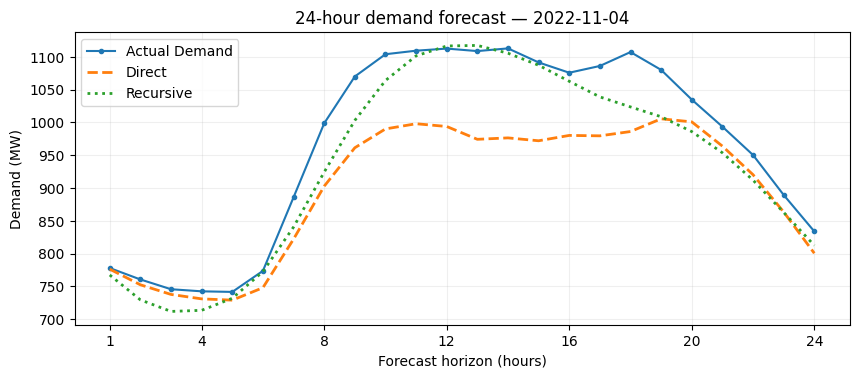

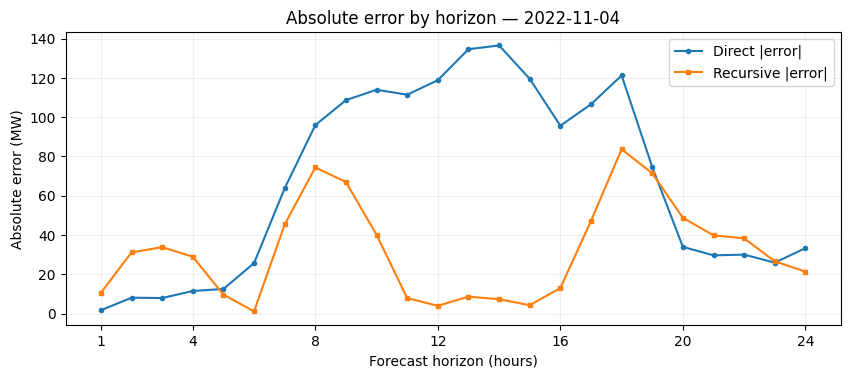

In [9]:
# Figure A: actual demand and 24-hour forecasts
hours = np.arange(1, 25)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hours, y, '-o', ms=3, label='Actual Demand')
ax.plot(hours, pred_direct, '--', lw=2, label='Direct')
ax.plot(hours, pred_recursive, ':', lw=2, label='Recursive')
ax.set(xlabel='Forecast horizon (hours)', ylabel='Demand (MW)',
       title=f'24-hour demand forecast — {FORECAST_DAY.date()}')
ax.set_xticks([1, 4, 8, 12, 16, 20, 24]); ax.legend()
plt.show()

# Figure B: per-horizon absolute errors (real output, not the illustration above)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hours, np.abs(y - pred_direct), '-o', ms=3, label='Direct |error|')
ax.plot(hours, np.abs(y - pred_recursive), '-s', ms=3, label='Recursive |error|')
ax.set(xlabel='Forecast horizon (hours)', ylabel='Absolute error (MW)',
       title=f'Absolute error by horizon — {FORECAST_DAY.date()}')
ax.set_xticks([1, 4, 8, 12, 16, 20, 24]); ax.legend()
plt.show()


### 👩‍🏫 Instructor notes — Exercise 1

**Reference implementation:** all forecasting functions, evaluation, and charts above are complete. The primary student edits are the configuration lines `HORIZONS`, `TRAIN_DAYS`, and `FORECAST_DAY`, not the forecaster implementation.

**Suggested demonstrations** (run one at a time):
- `[6, 12, 24]` → `[3, 6, 12, 24]` to visualize how aggregation over more steps changes NRMSE.
- `TRAIN_DAYS = 30` → `60`; compare both error curves.
- `FORECAST_DAY = pd.Timestamp('2022-11-05', tz=TZ)`; contrast Saturday with Friday.

**Expected interpretation:**
- Recursive feeds its own predictions back as lags, allowing error propagation; Direct does not. **However, Recursive need not be worse** for every test day/horizon.
- An error line need not increase monotonically: actual demand pattern, model bias and seasonal structure all matter.
- NRMSE for 6, 12, 24 h here is computed on nested prefixes of the **same 24-hour forecast**, so it is not a comparison of separately tuned models.
- The entire 24-hour horizon begins at 00:00 Tallinn time; a day-ahead industry forecast would often be issued earlier, requiring a more explicit issue-time setup.
- There is no future measured Demand in any model input. Timestamp/calendar features are known in advance.

**Answers to grade:** reason from their numeric output; no predetermined winner is guaranteed.


## Exercise 2 — Sliding vs. Expanding: how much history is useful?


Use the **same Direct forecaster** for all experiments. Only the range of historical training origins changes. Every strategy is evaluated on **exactly the same seven future days (4–10 November 2022)**.

- **Sliding 7/30/60:** fit on only the most recent 7, 30, or 60 training days.
- **Expanding from 30:** the first fold uses 30 days; each next fold adds one new day, retaining earlier training examples.

The illustration explains how the windows move. It is a schematic, not the output of the experiment.


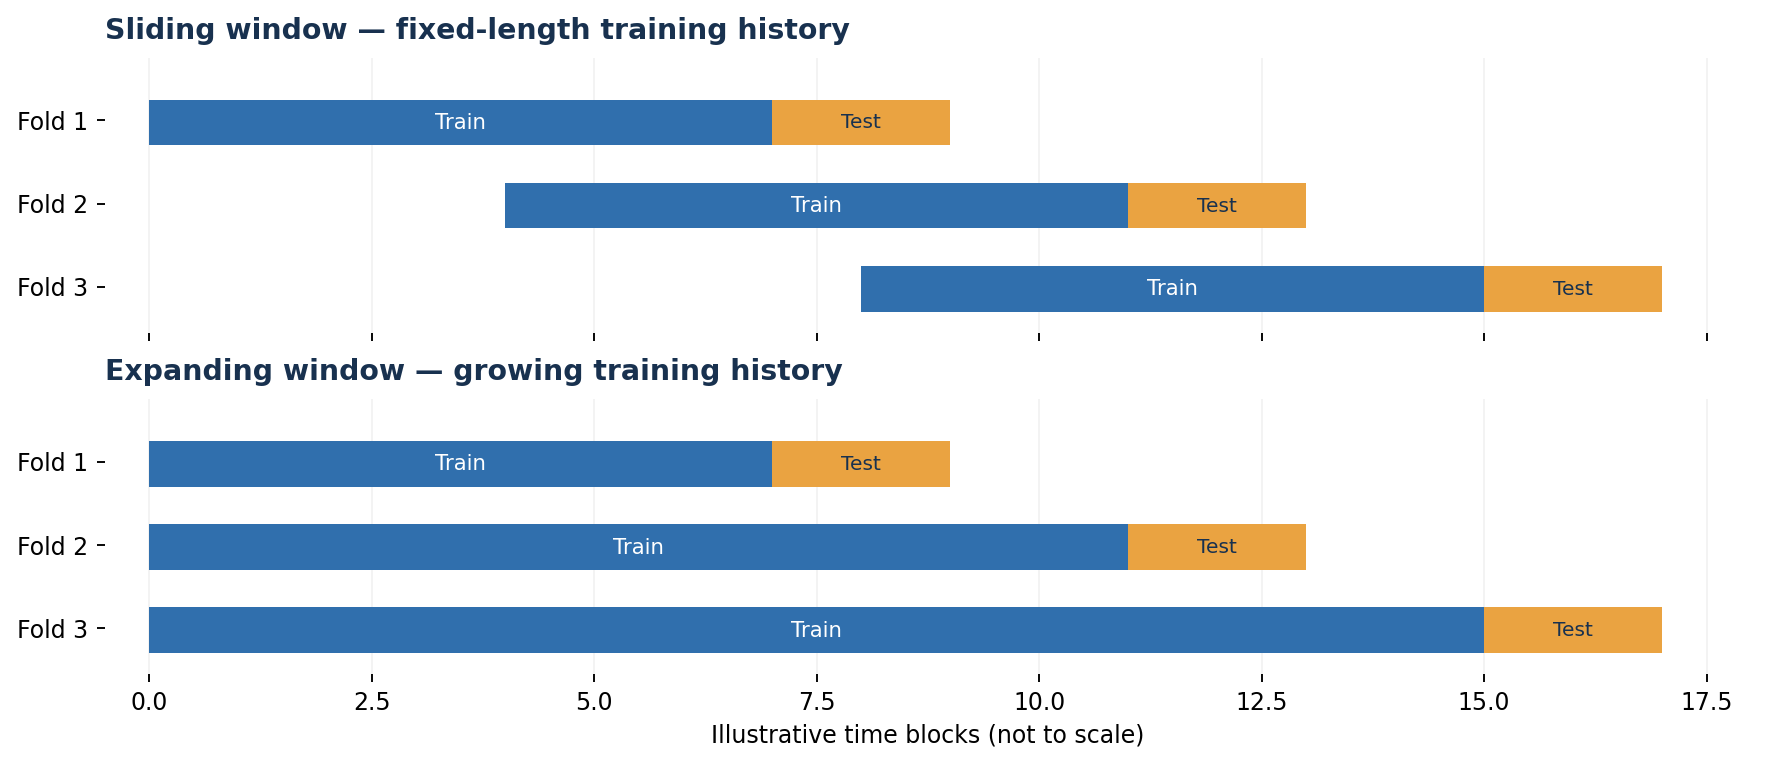


*Sliding and Expanding training windows: three schematic backtesting folds.*

### Your tasks

1. Run a 7-day backtest for the three **Sliding** windows and one **Expanding** window.
2. **TODO 4:** Try another Sliding window size (e.g. `14` days).
3. **TODO 5:** Change the initial Expanding window (e.g. `7` instead of `30` days), then re-run.
4. Examine the **average NRMSE** and the **day-to-day variation**. Which strategy seems most reliable?

For every test day, the model sees only historical observations that occurred *before that day*; it is refitted separately for each backtesting fold.


In [10]:
# TODO 4: change the candidate sliding windows.
SLIDING_WINDOWS = [7, 30, 60]
# TODO 5: change the initial size of the expanding window.
EXPANDING_INITIAL_DAYS = 30

TEST_DAYS = pd.date_range('2022-11-04', periods=7, freq='D', tz=TZ)
expanding_start = TEST_DAYS[0] - pd.DateOffset(days=EXPANDING_INITIAL_DAYS)

records = []
for forecast_day in TEST_DAYS:
    y_day = actual_values(demand, forecast_day, horizon=24)
    for window in SLIDING_WINDOWS:
        start = forecast_day - pd.DateOffset(days=window)
        predictions = forecast_direct(demand, forecast_day, start, horizon=24)
        records.append({
            'Test day': forecast_day.date(), 'Strategy': f'Sliding {window}d',
            'Training days': window, 'NRMSE (%)': nrmse(y_day, predictions)
        })

    predictions = forecast_direct(demand, forecast_day, expanding_start, horizon=24)
    effective_training_days = (forecast_day.date() - expanding_start.date()).days
    records.append({
        'Test day': forecast_day.date(), 'Strategy': f'Expanding {EXPANDING_INITIAL_DAYS}d start',
        'Training days': effective_training_days,
        'NRMSE (%)': nrmse(y_day, predictions)
    })

ex2_results = pd.DataFrame(records)
display(ex2_results.pivot(index='Test day', columns='Strategy', values='NRMSE (%)').round(2))
summary = (ex2_results.groupby('Strategy')['NRMSE (%)']
           .agg(['mean', 'std', 'min', 'max']).sort_values('mean'))
print('NRMSE summary — all values in %:')
display(summary.round(2))


Strategy,Expanding 30d start,Sliding 30d,Sliding 60d,Sliding 7d
Test day,,,,
2022-11-04,8.51,8.51,8.84,1.97
2022-11-05,5.47,5.41,6.07,5.94
2022-11-06,4.18,4.16,3.43,6.02
2022-11-07,5.88,5.75,7.72,10.31
2022-11-08,2.46,2.21,4.26,9.08
2022-11-09,1.69,1.88,1.65,4.13
2022-11-10,2.24,2.13,2.26,3.36


NRMSE summary — all values in %:


,mean,std,min,max
Strategy,,,,
Sliding 30d,4.29,2.45,1.88,8.51
Expanding 30d start,4.35,2.45,1.69,8.51
Sliding 60d,4.89,2.74,1.65,8.84
Sliding 7d,5.83,3.02,1.97,10.31


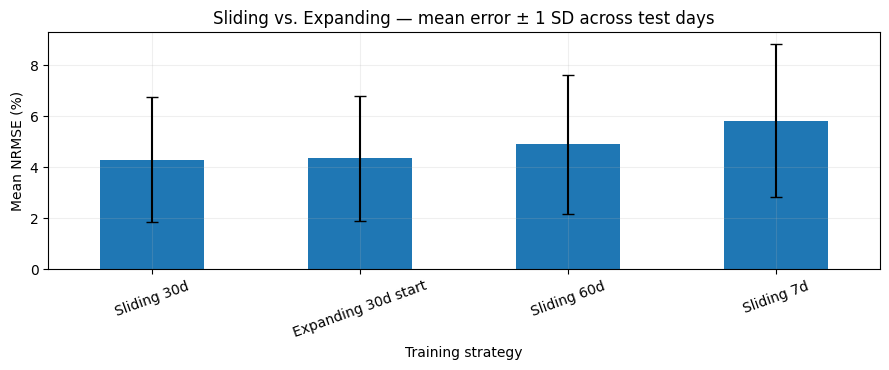

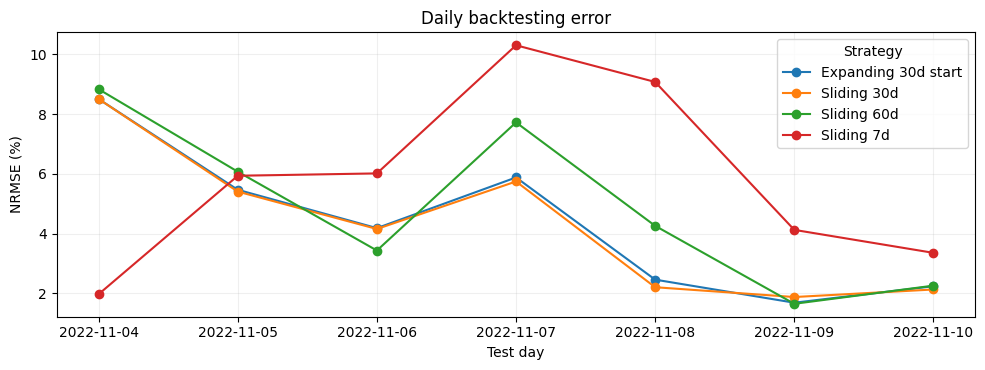

In [11]:
# Figure C: average NRMSE over the SAME test days
fig, ax = plt.subplots(figsize=(9, 3.8))
summary['mean'].plot(kind='bar', ax=ax, yerr=summary['std'], capsize=4)
ax.set(ylabel='Mean NRMSE (%)', xlabel='Training strategy',
       title='Sliding vs. Expanding — mean error ± 1 SD across test days')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

# Figure D: variation by test day (each line is a different training strategy)
fig, ax = plt.subplots(figsize=(10, 3.8))
ex2_results.pivot(index='Test day', columns='Strategy', values='NRMSE (%)').plot(ax=ax, marker='o')
ax.set(xlabel='Test day', ylabel='NRMSE (%)', title='Daily backtesting error')
plt.tight_layout(); plt.show()


### 👩‍🏫 Instructor notes — Exercise 2

**Answer key / interpretation:**
- Sliding windows use only the last **7, 30, or 60 calendar days**, recalculated for each test day.
- Expanding starts at **2022-10-05 00:00 Tallinn time** for the first fold (30 days before 2022-11-04) and grows by one calendar day for each subsequent test day.
- For fold 1, **Sliding 30d** and **Expanding 30d start** share exactly the same training start and are expected to give identical predictions/NRMSE (up to numerical roundoff). This is a useful correctness check.
- All four strategies predict **the same test days**, 2022-11-04 through 2022-11-10. Comparing means alone may hide outliers or instability; the SD and daily line plot add context.
- A short window may adapt faster to changing regimes but has more estimation variance. A large window may stabilize estimates but overrepresent older patterns. **More history does not guarantee lower error**.
- Possible examples of nonstationarity: weather regimes, public holidays, demand response, energy-price shocks, or changes in the consumer mix.
- 7 backtesting days are pedagogical, **not sufficient for a strong generalization claim**. For research, extend to many origins and preserve a final untouched holdout period.

**Important methodological nuance:** Data include an autumn DST transition in the historical interval. This lab constructs the hourly index from UTC epoch seconds, so repeated local clock times are represented unambiguously. On the chosen test days, each test block is exactly 24 physical hours.

**Automatic correctness checks:**


In [12]:
# A quick diagnostic: first fold Expanding(30) should equal Sliding(30).
first_fold = ex2_results[ex2_results['Test day'] == TEST_DAYS[0].date()]
sliding_first = float(first_fold.loc[first_fold['Strategy'] == 'Sliding 30d', 'NRMSE (%)'].iloc[0])
expanding_first = float(first_fold.loc[first_fold['Strategy'] == 'Expanding 30d start', 'NRMSE (%)'].iloc[0])
assert np.isclose(sliding_first, expanding_first), 'Fold-1 30-day windows should match.'
assert (ex2_results.groupby('Strategy')['Test day'].nunique() == len(TEST_DAYS)).all()
print('Checks passed: identical first-fold 30d windows; consistent evaluation days.')


Checks passed: identical first-fold 30d windows; consistent evaluation days.


### Optional extension

**Advanced discussion:** compare these models with seasonal naïve (last day or same weekday last week), and explain why evaluating only 7 days may produce an unstable ranking.